![Banner](../../../../Images/Banner/07_remote_sensing/09_08_banner_rs_super_resolution.png)


# Sentinel-2 to PlanetScope: multispectral super-resolution

This tutorial follows the workflow of `07_07_01_Landsat8_to_Sentinel2_Super_Resolution.ipynb`, reversing the sensor roles: **Sentinel-2 Level-2A at 10 m** is the input, and the supplied **PlanetScope 4-band image at 3 m** is the finer reference.


## Overview

The data are from folders labeled July 8, 2019; the PlanetScope GeoTIFF sidecars do not provide a verifiable acquisition timestamp, so exact temporal coincidence cannot be confirmed here.

The comparison uses four common channels in the order **blue, green, red, NIR**. Sentinel-2 B02/B03/B04/B08 are used; PlanetScope's TIFF bands have generic labels, so their order is explicitly assumed to be blue/green/red/NIR. The PlanetScope TIFF is UInt16 and the included sidecar has no radiometric scale factor. For this demonstration, `PLANET_SCALE_TO_REFLECTANCE = 0.0001` is an explicit assumption based on the common PlanetScope integer reflectance encoding; verify it and the band order against the original Planet product metadata before interpreting numerical scores scientifically.

The workflow reprojects PlanetScope from NAD83 / UTM zone 17N to the Sentinel-2 CRS, then aligns it to the 3 m output grid. It compares interpolation and unsharp masking with an EDSR-style CNN trained on spatially separate Sentinel/Planet patches. Validation scores measure agreement with this one PlanetScope reference, not absolute Sentinel-2 truth. Sensor spectral response, co-registration, unknown PlanetScope radiometry, date mismatch, and the tiny study area limit generalization. A 3 m output grid is not proof of 3 m Sentinel-2 information.


## Workflow and GeoLattice functions

1. Read Sentinel-2 and PlanetScope rasters with `geolattice.rsense.read`, inspect their metadata and make the Planet radiometry assumption visible.
2. Reproject PlanetScope and align it to the finer grid generated by GeoLattice `super_resolution.upsample`.
3. Build clear/finite masks, inspect the imagery, and run classical interpolation baselines.
4. Create co-registered 10 m/3 m training patches, spatially hold out validation patches, and train a GeoLattice EDSR-style model.
5. Compare the estimates against held-out PlanetScope pixels and export the masked products with `geolattice.rsense.write` as COGs.

Install GeoLattice and optional neural dependencies with `pip install "geolattice[rsense-dl]"`. The 10-to-3 m ratio is non-integer (10/3); GeoLattice supports arbitrary scale factors and rounds output dimensions to the nearest pixel.


### Imports, paths, and experiment settings

This cell imports GeoLattice for geospatial raster operations, NumPy/PyTorch for arrays and model training, and plotting utilities. It finds the repository so the notebook can use the current source checkout when available. Input paths point to the supplied folders. PlanetScope channel names and its scale factor are declared as assumptions rather than inferred from incomplete TIFF tags. `PATCH` is measured in 10 m Sentinel pixels; each 24-pixel patch maps to approximately 80 PlanetScope 3 m pixels.


**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README.

In [1]:
from pathlib import Path  # file paths
import json  # read the scene metadata JSON
import os  # environment variables and CPU count
import sys  # Python import path

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import torch  # PyTorch: the neural super-resolution model
import xarray as xr  # labelled arrays and result tables
from rasterio.enums import Resampling  # resampling methods
from scipy.ndimage import distance_transform_edt  # distance to the nearest valid pixel (gap filling)
from torch.utils.data import DataLoader, TensorDataset  # feed patches to PyTorch in batches

# Prefer the GeoLattice source tree when the notebook is run from this repository.
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "pyproject.toml").exists() and (p / "src" / "rsense").is_dir()), None)
if ROOT is not None:  # a checkout was found
    sys.path.insert(0, str(ROOT / "src"))  # import GeoLattice from its src folder

from geolattice import rsense as rs  # GeoLattice remote sensing
from geolattice.rsense import super_resolution as sr  # super-resolution tools

if ROOT is None:  # not started inside the repository
    # stop with a clear message
    raise FileNotFoundError("Start Jupyter from the GeoLattice checkout or one of its subdirectories")
# this notebook's folder
NOTEBOOK_DIR = ROOT / "Tutorials" / "notebooks" / "08_remote_sensing" / "09_08_image_super_resolution"
DATA_DIR = NOTEBOOK_DIR / "../../../../Data/08_remote_sensing/08_08_image_super_resolution"  # its data folder
SENTINEL_DIR = DATA_DIR / "Sentinel_2" / "L2A_T17TQH_20190708"  # Sentinel-2 scene folder
PLANET_DIR = DATA_DIR / "Planet" / "July_08_2019"  # PlanetScope folder
# Sentinel-2 surface reflectance, 10 m
SENTINEL_PATH = SENTINEL_DIR / "sentinel2_20190708_surface_reflectance_6band_10m.tif"
SENTINEL_MASK_PATH = SENTINEL_DIR / "clear_mask_10m.tif"  # Sentinel-2 clear-sky mask
PLANET_PATH = PLANET_DIR / "Planet_Rural_AOI_July_08_2019.tif"  # the PlanetScope image
# Every input is a prepared clip of the study area kept in data/; there is no public download
# for these clips, so stop with a clear message when one is missing from the local drive.
INPUTS = [SENTINEL_PATH, SENTINEL_MASK_PATH, PLANET_PATH]  # the input rasters of this notebook
missing = [str(p) for p in INPUTS if not p.exists()]  # inputs not found on the local drive
if missing:  # stop early with the list of missing files
    raise FileNotFoundError("Copy these files into the data folder first: " + ", ".join(missing))
print("Reading", len(INPUTS), "input rasters from", DATA_DIR)  # all inputs are local

OUTPUT_DIR = Path(os.environ.get(  # output folder (can be changed with an environment variable)
    "GEOLATTICE_SR_OUTPUT", DATA_DIR / "super_resolution_outputs_s2_to_planet"
))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)  # create it if needed

BANDS = ["blue", "green", "red", "nir"]  # the four bands both sensors share
SCALE = 10 / 3  # 10 m Sentinel-2 pixels to the PlanetScope 3 m grid
PLANET_SCALE_TO_REFLECTANCE = 0.0001  # Assumed encoding; confirm in source metadata.
PATCH = 24  # low-resolution patch width in 10 m pixels
SEED = 23  # random seed
torch.manual_seed(SEED)  # same initial weights on every run
torch.set_num_threads(min(4, os.cpu_count() or 1))  # use at most four CPU threads
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # use the GPU when available
print("GeoLattice checkout:", ROOT)  # repository path
print("PyTorch:", torch.__version__, "| device:", DEVICE)  # PyTorch version and device
print("Output folder:", OUTPUT_DIR)  # output folder
print("PlanetScope scale assumption:", PLANET_SCALE_TO_REFLECTANCE)  # the assumed PlanetScope scale factor

GeoLattice checkout: /media/zia207/SSD/GitHub/GeoLattice
PyTorch: 2.10.0+cu128 | device: cuda
Output folder: /media/zia207/SSD/GitHub/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_08_image_super_resolution/data/super_resolution_outputs_s2_to_planet
PlanetScope scale assumption: 0.0001


### Read scenes and establish the shared band order

`rs.read` loads rasters into georeferenced xarray `DataArray` objects, preserving coordinate systems and nodata masks. Sentinel-2 has six channels; this cell selects blue, green, red, and B08 NIR for comparison. PlanetScope's four bands are named explicitly because the supplied TIFF labels are generic. The metadata JSON documents Sentinel-2 dates, band IDs, and native resolutions; the Planet TIFF's own XML/auxiliary metadata does not document band order, reflectance scaling, or an exact scene timestamp.


In [2]:
sentinel_metadata = json.loads((SENTINEL_DIR / "metadata.json").read_text())  # Sentinel-2 scene metadata

sentinel_all = rs.read(  # read the Sentinel-2 stack with band names
    SENTINEL_PATH,
    band_names=["blue", "green", "red", "nir", "swir1", "swir2"],
)
sentinel = sentinel_all.sel(band=BANDS)  # keep the four shared bands

# The source PlanetScope file has four generic bands (Band_1 ... Band_4).
# This tutorial assumes their conventional 4-band order: blue, green, red, NIR.
planet_dn = rs.read(PLANET_PATH, band_names=BANDS)
# PlanetScope DN -> reflectance with the assumed scale factor
planet = (planet_dn.astype("float32") * PLANET_SCALE_TO_REFLECTANCE)

sentinel_clear = rs.read(  # Sentinel-2 clear mask
    SENTINEL_MASK_PATH, band_names=["clear"]
).isel(band=0, drop=True)

print("Sentinel-2 scene:", sentinel_metadata["scene_id"])  # scene ID
print("Sentinel acquired:", sentinel_metadata["acquired"])  # acquisition date
print("Planet file:", PLANET_PATH.name, "| TIFF CRS:", planet_dn.rio.crs)  # PlanetScope file and CRS
print("Sentinel shape/bands:", sentinel.shape, list(sentinel.band.values))  # Sentinel-2 shape and bands
print("Planet shape/bands (assumed):", planet.shape, list(planet.band.values))  # PlanetScope shape and bands
print("Planet raw DN percentiles:", np.nanpercentile(planet_dn.values, [1, 50, 99]))  # raw DN percentiles
print("Planet scaled percentiles:", np.nanpercentile(planet.values, [1, 50, 99]))  # scaled percentiles
# date note
print("Planet acquisition date: folder is labeled July 8, 2019; exact timestamp unavailable in sidecar")

Sentinel-2 scene: S2A_MSIL2A_20190708T155911_R097_T17TQH_20201005T110153
Sentinel acquired: 2019-07-08T15:59:11.024000+00:00
Planet file: Planet_Rural_AOI_July_08_2019.tif | TIFF CRS: EPSG:26917
Sentinel shape/bands: (4, 609, 567) [np.str_('blue'), np.str_('green'), np.str_('red'), np.str_('nir')]
Planet shape/bands (assumed): (4, 2291, 2170) [np.str_('blue'), np.str_('green'), np.str_('red'), np.str_('nir')]


Planet raw DN percentiles: [ 361.  842. 4886.]
Planet scaled percentiles: [0.0361     0.08419999 0.48859999]
Planet acquisition date: folder is labeled July 8, 2019; exact timestamp unavailable in sidecar


### Build the PlanetScope reference on the 3 m target grid

The PlanetScope scene is in NAD83 / UTM zone 17N (EPSG:26917); Sentinel-2 is in WGS 84 / UTM zone 17N (EPSG:32617). We first reproject the PlanetScope raster with GeoLattice at 3 m resolution. Then `rio.reproject_match` aligns it exactly to the 3 m xarray grid created by `sr.upsample` from Sentinel-2. This removes the grid-origin and CRS mismatch before pairing patches. Bilinear resampling is used only to account for the coordinate transformation and alignment; it does not add PlanetScope detail.


In [3]:
# Create the exact 3 m grid that GeoLattice will use for each SR output.
planet_grid = sr.upsample(sentinel, SCALE, method="bicubic")

# Convert the clipped PlanetScope image to Sentinel-2's CRS, retaining 3 m pixels.
planet_in_sentinel_crs = rs.reproject(
    planet, dst_crs=sentinel.rio.crs, resolution=3.0, resampling="bilinear"
)

# Match the 3 m template's transform and shape exactly, not just its CRS/resolution.
planet_reference = planet_in_sentinel_crs.rio.reproject_match(
    planet_grid, resampling=Resampling.bilinear
).assign_coords(band=BANDS)
planet_reference = planet_reference.rio.write_nodata(np.nan)  # NaN marks no data

assert planet_reference.rio.crs == planet_grid.rio.crs  # same CRS as the target grid
assert planet_reference.shape == planet_grid.shape  # same shape
assert np.allclose(planet_reference.rio.transform(), planet_grid.rio.transform())  # same transform
print("Sentinel grid:", sentinel.rio.crs, sentinel.rio.resolution(), sentinel.rio.bounds())  # Sentinel-2 grid
print("Planet target grid:", planet_reference.rio.crs,  # the 3 m target grid
      planet_reference.rio.resolution(), planet_reference.shape)
print("Shared bounds:", planet_reference.rio.bounds())  # the shared extent

Sentinel grid: EPSG:32617 (10.0, -10.0) (747075.0, 4742115.0, 752745.0, 4748205.0)
Planet target grid: EPSG:32617 (3.0, -3.0) (4, 2030, 1890)
Shared bounds: (747075.0, 4742115.0, 752745.0, 4748205.0)


### Create valid-pixel masks and fill only for model input

Sentinel-2's clear mask uses 1 for clear pixels; nodata and all non-clear classes are excluded. PlanetScope has no separate clear mask in the supplied folder, so finite, non-nodata reflectance is used as the available validity test. The shared high-resolution mask additionally requires the nearest-resampled Sentinel mask to be clear. Temporary nearest-neighbor filling makes model input arrays finite; those filled locations are never allowed into training, scoring, or final exports.


In [4]:
sentinel_values = np.asarray(sentinel.values, dtype="float32")  # Sentinel-2 as a float array
# PlanetScope (on the 3 m grid) as a float array
planet_values = np.asarray(planet_reference.values, dtype="float32")
# clear and finite in every band
sentinel_valid = (sentinel_clear.values == 1) & np.isfinite(sentinel_values).all(axis=0)
planet_valid = np.isfinite(planet_values).all(axis=0)  # finite in every band

# Upsample the low-resolution clear mask with nearest neighbour to the target grid.
sentinel_mask_da = sentinel.isel(band=0, drop=True).copy(
    data=sentinel_valid.astype("float32")
)
sentinel_valid_hr = np.asarray(  # the clear mask on the 3 m grid
    sr.upsample(sentinel_mask_da, SCALE, method="nearest").values > 0.5
)
valid_pair_hr = sentinel_valid_hr & planet_valid  # pixels valid in both on the 3 m grid
if not sentinel_valid.any() or not planet_valid.any() or not valid_pair_hr.any():  # nothing valid
    raise ValueError("The scenes have no valid overlapping pixels")  # stop with a clear message

def fill_invalid_nearest(cube, valid):  # fill invalid pixels with the nearest valid value
    """Temporarily fill invalid (band, y, x) values from their nearest valid pixel."""
    if not valid.any():  # nothing to fill from
        raise ValueError("Cannot fill an image with no valid pixels")  # stop with a clear message
    # row and column of the nearest valid pixel
    rows, cols = distance_transform_edt(~valid, return_distances=False, return_indices=True)
    filled = np.asarray(cube, dtype="float32").copy()  # copy of the cube
    for band in range(filled.shape[0]):  # every band
        filled[band, ~valid] = filled[band, rows[~valid], cols[~valid]]  # copy the nearest valid value
    return filled  # the filled cube

sentinel_filled = fill_invalid_nearest(sentinel_values, sentinel_valid)  # Sentinel-2 with gaps filled
planet_filled = fill_invalid_nearest(planet_values, planet_valid)  # PlanetScope with gaps filled
sentinel_filled_da = sentinel.copy(data=sentinel_filled)  # filled Sentinel-2 as a georeferenced DataArray
print("Valid Sentinel-2 pixels:", f"{sentinel_valid.mean():.1%}")  # valid Sentinel-2 share
print("Valid PlanetScope pixels on output grid:", f"{planet_valid.mean():.1%}")  # valid PlanetScope share
print("Valid paired output pixels:", f"{valid_pair_hr.mean():.1%}")  # valid paired share

Valid Sentinel-2 pixels: 86.8%
Valid PlanetScope pixels on output grid: 86.8%
Valid paired output pixels: 86.7%


### Make comparable RGB displays

This display helper selects red, green, and blue from each four-band cube and applies a per-image percentile stretch for visibility. Stretches are computed independently for PlanetScope and Sentinel-2, so the plotted colors are not a radiometric comparison. The input Sentinel view is at native 10 m; the PlanetScope view is on the matched 3 m grid.


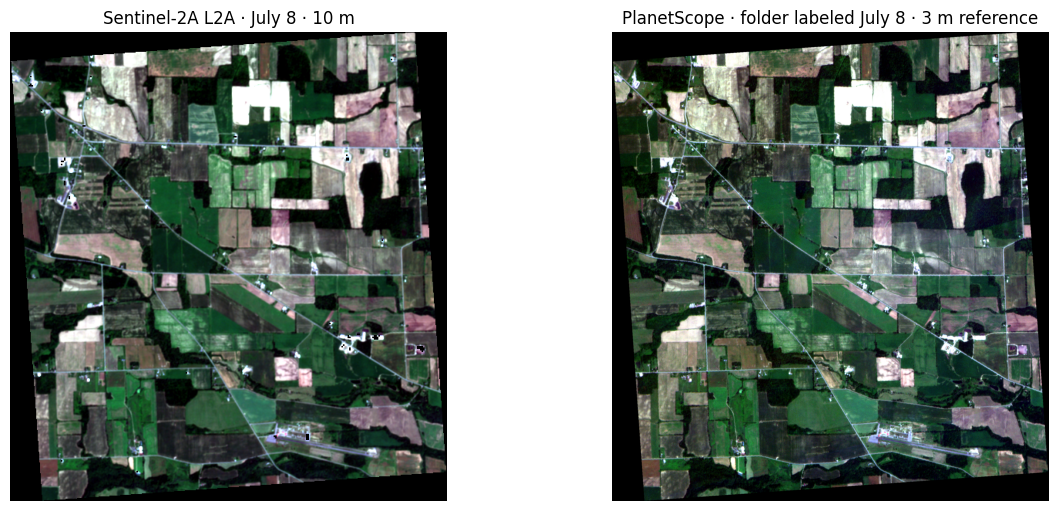

In [ ]:
def rgb_stretch(cube, valid, bands=(2, 1, 0), percentiles=(2, 98)):  # contrast-stretched RGB image of a cube
    """Return a contrast-stretched RGB view from a (band, y, x) cube."""
    rgb = cube[list(bands)].transpose(1, 2, 0).copy()  # bands red, green, blue -> (rows, cols, 3)
    keep = valid & np.isfinite(rgb).all(axis=-1)  # valid pixels
    for channel in range(3):  # each colour channel
        values = rgb[..., channel][keep]  # its valid values
        low, high = np.percentile(values, percentiles)  # percentile limits
        rgb[..., channel] = np.clip(  # stretch to [0, 1]
            (rgb[..., channel] - low) / max(high - low, 1e-6), 0, 1
        )
    rgb[~keep] = 0  # invalid pixels in black
    return rgb  # the RGB image

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)  # two panels
axes[0].imshow(rgb_stretch(sentinel_filled, sentinel_valid))  # Sentinel-2
axes[0].set_title("Sentinel-2A L2A · July 8 · 10 m")  # title
axes[1].imshow(rgb_stretch(planet_filled, planet_valid))  # PlanetScope
axes[1].set_title("PlanetScope ·  July 8 · 3 m reference")  # title
for ax in axes:  # for both panels
    ax.set_axis_off()  # no axes
plt.show()  # draw

## Classical methods

### Create interpolation and sharpening baselines

GeoLattice `upsample` provides nearest, bilinear, bicubic, and Lanczos estimates on the exact output grid. `unsharp_mask` adds local high-frequency contrast to bicubic interpolation. The model ratio is 10/3, so iterative back-projection (which requires an integer factor) is not included. These estimates are spatial resamplings of Sentinel-2; they cannot restore detail absent from its 10 m measurements.


In [6]:
classical_da = {  # four interpolation methods to the 3 m grid
    "Nearest": sr.upsample(sentinel_filled_da, SCALE, method="nearest"),
    "Bilinear": sr.upsample(sentinel_filled_da, SCALE, method="bilinear"),
    "Bicubic": sr.upsample(sentinel_filled_da, SCALE, method="bicubic"),
    "Lanczos": sr.upsample(sentinel_filled_da, SCALE, method="lanczos"),
}
classical = {name: np.asarray(image.values, dtype="float32")  # their values as arrays
             for name, image in classical_da.items()}
classical["Unsharp bicubic"] = sr.unsharp_mask(  # mild sharpening of the bicubic result
    classical["Bicubic"], amount=0.5, sigma=1.0
)
assert all(cube.shape == planet_values.shape for cube in classical.values())  # all have the PlanetScope shape
print({name: cube.shape for name, cube in classical.items()})  # their shapes

{'Nearest': (4, 2030, 1890), 'Bilinear': (4, 2030, 1890), 'Bicubic': (4, 2030, 1890), 'Lanczos': (4, 2030, 1890), 'Unsharp bicubic': (4, 2030, 1890)}


## Deep learning: paired multispectral EDSR-style CNN

### Build spatially separated 10 m / 3 m patch pairs

Each 24×24 Sentinel-2 patch is paired with an 80×80 PlanetScope reference patch (rounding 24×10/3 to the nearest output pixels). Patches must be at least 98% valid in both the Sentinel input and Planet reference. A deterministic block split assigns neighboring patches together to training or validation, reducing leakage from adjacent pixels. Because PlanetScope's exact capture time and radiometric scale are not supplied in the sidecar, this is a site-specific demonstration; validation is against the aligned Planet reference, not an independent sensor-calibrated truth.


In [7]:
HR_PATCH = round(PATCH * SCALE)  # size of a target patch on the 3 m grid
patch_records = []  # every usable patch: position, input, target, validation flag
height, width = sentinel_valid.shape  # Sentinel-2 image size
for row in range(0, height - PATCH + 1, PATCH):  # patch rows
    for col in range(0, width - PATCH + 1, PATCH):  # patch columns
        low_valid_patch = sentinel_valid[row:row + PATCH, col:col + PATCH]  # Sentinel-2 validity of the patch
        high_row, high_col = round(row * SCALE), round(col * SCALE)  # matching position on the 3 m grid
        # skip patches that run off the 3 m grid
        if high_row + HR_PATCH > planet_values.shape[1] or high_col + HR_PATCH > planet_values.shape[2]:
            continue
        high_valid_patch = valid_pair_hr[  # validity of the matching 3 m patch
            high_row:high_row + HR_PATCH, high_col:high_col + HR_PATCH
        ]
        # keep patches at least 98 % valid in both
        if low_valid_patch.mean() >= 0.98 and high_valid_patch.mean() >= 0.98:
            low_patch = sentinel_filled[:, row:row + PATCH, col:col + PATCH]  # the 10 m input patch
            high_patch = planet_filled[:, high_row:high_row + HR_PATCH,  # the 3 m target patch
                                       high_col:high_col + HR_PATCH]
            # Keep each 2-by-2 group of adjacent patches in one split.
            tile_row, tile_col = row // PATCH, col // PATCH
            # every fifth 2 x 2 block of patches is held out
            validation = ((tile_row // 2 + tile_col // 2) % 5) == 0
            patch_records.append((row, col, low_patch.copy(), high_patch.copy(), validation))  # store the patch

train_records = [record for record in patch_records if not record[4]]  # training patches
validation_records = [record for record in patch_records if record[4]]  # validation patches
if len(train_records) < 8 or len(validation_records) < 2:  # too few of either
    # stop with a clear message
    raise RuntimeError(f"Too few clear paired patches: {len(train_records)} train, "
                       f"{len(validation_records)} validation")
# training inputs as a tensor
X_train = torch.from_numpy(np.stack([record[2] for record in train_records])).float()
Y_train = torch.from_numpy(np.stack([record[3] for record in train_records])).float()  # training targets
# shuffled batches of 8 patches
train_loader = DataLoader(TensorDataset(X_train, Y_train), batch_size=8, shuffle=True)
print(f"Paired patches: {len(patch_records)} total; {len(train_records)} train; "  # patch counts
      f"{len(validation_records)} held out")
print("Training tensor shapes:", tuple(X_train.shape), tuple(Y_train.shape),  # tensor shapes
      "| model scale:", SCALE)

Paired patches: 467 total; 371 train; 96 held out
Training tensor shapes: (371, 4, 24, 24) (371, 4, 80, 80) | model scale: 3.3333333333333335


### Train the GeoLattice EDSR-style network

`build_sr_model` constructs a four-band EDSR-style CNN with the non-integer 10/3 scale. `train_super_resolution` optimizes L1 reflectance error, spectral-angle loss, and coarse-observation consistency. Consistency asks the fine estimate to remain compatible with the low-resolution input, but does not make the inferred detail unique. Training on one small paired scene can overfit its land-cover patterns; the spatial holdout and independent scenes are important checks.


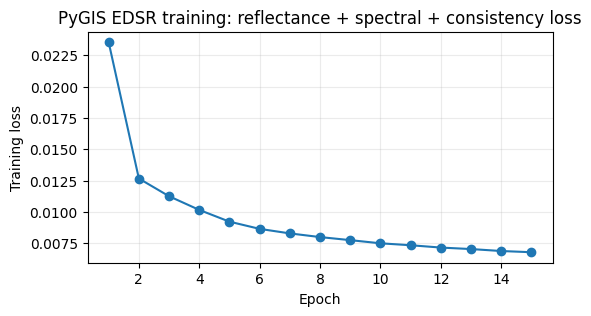

In [8]:
model = sr.build_sr_model(  # an EDSR network with 24 features and 3 residual blocks
    in_channels=len(BANDS), scale=SCALE, features=24, blocks=3, architecture="edsr"
)
history = sr.train_super_resolution(  # train it for 15 epochs
    model, train_loader, epochs=15, lr=1e-4, device=DEVICE,
    sam_weight=0.05, consistency_weight=0.05,
)

fig, ax = plt.subplots(figsize=(6, 3))  # one panel
# training loss per epoch
ax.plot(np.arange(1, len(history["train_loss"]) + 1), history["train_loss"], marker="o")
ax.set(xlabel="Epoch", ylabel="Training loss",  # labels and title
       title="GeoLattice EDSR training: reflectance + spectral + consistency loss")
ax.grid(alpha=0.25)  # grid
plt.show()  # draw

## Inference and held-out evaluation

### Tiled inference and reference metrics

`predict_super_resolution` runs the model on overlapping tiles and blends them to reduce edge seams. The xarray input lets GeoLattice preserve georeferencing on the finer output grid. Held-out RMSE, PSNR, and SAM are computed only over validation patches with valid PlanetScope and Sentinel pixels. PSNR assumes reflectance in [0,1]. Because PlanetScope's radiometric encoding and exact acquisition time are undocumented in the supplied TIFF sidecars, treat these figures as diagnostics under the stated assumptions, not as certified accuracy.


In [9]:
# apply the network to the whole Sentinel-2 image in overlapping 64-pixel tiles
neural_da = sr.predict_super_resolution(
    model, sentinel_filled_da, tile=64, overlap=12, batch_size=4, device=DEVICE
)
neural = np.asarray(neural_da.values, dtype="float32")  # the prediction as an array
assert neural.shape == planet_values.shape  # same shape as the reference

candidates = {**classical, "CNN (paired patches)": neural}  # classical estimates plus the network

def heldout_metrics(prediction):  # scores on the held-out patches only
    """Calculate RMSE, unit-range PSNR, and SAM over spatial holdout patches."""
    estimates, references = [], []  # pieces of prediction and reference
    for row, col, _, _, _ in validation_records:  # every validation patch
        high_row, high_col = round(row * SCALE), round(col * SCALE)  # its position on the 3 m grid
        mask = valid_pair_hr[high_row:high_row + HR_PATCH,  # valid pixels of the patch
                             high_col:high_col + HR_PATCH]
        if not mask.any():  # skip patches without valid pixels
            continue
        estimates.append(prediction[:, high_row:high_row + HR_PATCH,  # the predicted patch, valid pixels only
                                    high_col:high_col + HR_PATCH][:, mask])
        # the reference patch, valid pixels only
        references.append(planet_values[:, high_row:high_row + HR_PATCH,
                                        high_col:high_col + HR_PATCH][:, mask])
    if not estimates:  # nothing to score
        raise ValueError("No valid validation pixels are available")  # stop with a clear message
    estimate = np.concatenate(estimates, axis=1)  # all prediction pixels
    reference = np.concatenate(references, axis=1)  # all reference pixels
    rmse = float(np.sqrt(np.mean((estimate - reference) ** 2)))  # root-mean-square error
    dot = np.sum(estimate * reference, axis=0)  # dot product of the spectra
    norms = np.linalg.norm(estimate, axis=0) * np.linalg.norm(reference, axis=0)  # product of their lengths
    # spectral angle of every pixel
    angle = np.degrees(np.arccos(np.clip(dot / np.maximum(norms, 1e-8), -1, 1)))
    return {"RMSE": rmse,  # RMSE, PSNR and mean spectral angle
            "PSNR (range=1)": float(20 * np.log10(1 / max(rmse, 1e-12))),
            "SAM (degrees)": float(angle.mean())}

scores = {name: heldout_metrics(prediction) for name, prediction in candidates.items()}  # score every method
score_table = xr.Dataset({  # scores as a table
    metric: xr.DataArray([scores[name][metric] for name in scores], dims="method",
                         coords={"method": list(scores)})
    for metric in next(iter(scores.values()))
}).to_dataframe()
display(score_table.sort_values("RMSE").style.format("{:.4f}"))  # best method first

,RMSE,PSNR (range=1),SAM (degrees)
method,,,
CNN (paired patches),0.0080,41.9713,0.9435
Bilinear,0.0206,33.7337,3.6607
Lanczos,0.0206,33.7019,3.6691
Bicubic,0.0209,33.6166,3.7060
Unsharp bicubic,0.0210,33.5725,3.7217
Nearest,0.0214,33.3782,3.7756


### Visualize the PlanetScope reference and estimates

The panels use a common RGB stretch derived from valid PlanetScope pixels, which keeps color display comparable across the reference and predictions. Sentinel-2 is shown at its 10 m grid enlarged to 3 m; the interpolation panels and CNN are all on the same target grid. Plot masking hides cloud/nodata pixels and the outside-AOI area.


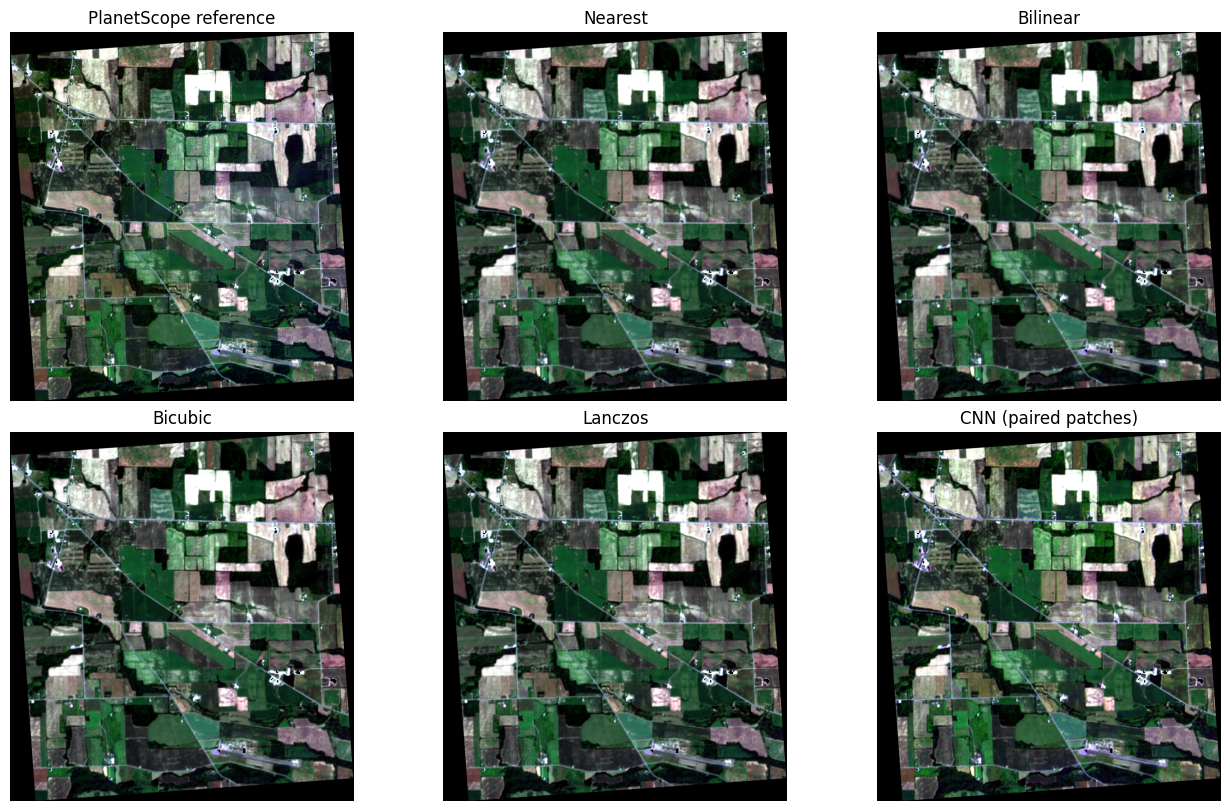

In [10]:
image_sets = {"PlanetScope reference": planet_filled, **candidates}  # the reference plus every estimate
plot_order = ["PlanetScope reference", "Nearest", "Bilinear", "Bicubic",  # panel order
              "Lanczos", "CNN (paired patches)"]
fig, axes = plt.subplots(2, 3, figsize=(13, 8), constrained_layout=True)  # 2 x 3 panels
for ax, name in zip(axes.flat, plot_order):  # one panel per image
    ax.imshow(rgb_stretch(image_sets[name], valid_pair_hr))  # RGB view, valid pixels only
    ax.set_title(name)  # title
    ax.set_axis_off()  # no axes
plt.show()  # draw

## Export georeferenced products with GeoLattice

### Restore nodata and write Cloud-Optimized GeoTIFFs

The 3 m grid from `planet_grid` supplies the exact CRS, transform, coordinates, and channel names for every output. Temporary nearest-neighbor fills are replaced with NaN wherever either scene is invalid. `rs.write` creates COGs. The metadata records the input/reference scenes, scale assumption, and the fact that the product is a model estimate on a 3 m grid-not a native Sentinel-2 observation.


In [11]:
template_3m = planet_grid  # the 3 m grid as template
output_valid = valid_pair_hr  # pixels valid in both images

def as_valid_georeferenced(cube, method_name):  # wrap an estimate as a georeferenced DataArray
    """Wrap an array on the shared 3 m grid and restore invalid pixels as nodata."""
    values = np.where(output_valid[None, :, :], cube, np.nan).astype("float32")  # invalid pixels -> NaN
    # the template with these values and NaN as no-data
    result = template_3m.copy(data=values).rio.write_nodata(np.nan)
    result.attrs = {  # record what the file contains
        "method": method_name,
        "input_scene": sentinel_metadata["scene_id"],
        "reference_file": PLANET_PATH.name,
        "planet_scale_assumption": PLANET_SCALE_TO_REFLECTANCE,
        "interpretation": "3 m output grid; estimated detail is not native Sentinel-2 measurement",
    }
    return result  # the DataArray

for name, cube in candidates.items():  # every estimate
    safe_name = name.lower().replace(" ", "_").replace("(", "").replace(")", "")  # a file-safe name
    output_path = OUTPUT_DIR / f"{safe_name}.tif"  # output path
    rs.write(as_valid_georeferenced(cube, name), output_path, cog=True)  # save as a Cloud-Optimised GeoTIFF
    print("Wrote", output_path)  # report the file

Wrote /media/zia207/SSD/GitHub/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_08_image_super_resolution/data/super_resolution_outputs_s2_to_planet/nearest.tif


Wrote /media/zia207/SSD/GitHub/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_08_image_super_resolution/data/super_resolution_outputs_s2_to_planet/bilinear.tif


Wrote /media/zia207/SSD/GitHub/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_08_image_super_resolution/data/super_resolution_outputs_s2_to_planet/bicubic.tif


Wrote /media/zia207/SSD/GitHub/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_08_image_super_resolution/data/super_resolution_outputs_s2_to_planet/lanczos.tif


Wrote /media/zia207/SSD/GitHub/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_08_image_super_resolution/data/super_resolution_outputs_s2_to_planet/unsharp_bicubic.tif


Wrote /media/zia207/SSD/GitHub/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_08_image_super_resolution/data/super_resolution_outputs_s2_to_planet/cnn_paired_patches.tif


## Interpretation and limitations

- **Nearest, bilinear, bicubic, and Lanczos** are resampling baselines; they do not recover detail absent from Sentinel-2.
- **Unsharp masking** increases local contrast and can amplify noise or create overshoot.
- **The EDSR-style CNN** learns from the supplied Sentinel-2/PlanetScope pair. A spatial holdout is useful but is not an independent-scene test; it cannot establish transfer to another date, site, or sensor.
- The PlanetScope TIFF is labeled `Band_1`-`Band_4`, with no radiometric scale or capture timestamp in the supplied sidecars. This notebook assumes blue/green/red/NIR order and a 0.0001 scale factor; verify both from the original Planet metadata before relying on reflectance metrics.
- The scenes use different CRS definitions and have been reprojected to a common 3 m grid. Remaining co-registration error can be learned as false edges. Compare image boundaries and stable features before interpreting fine detail.
- Sentinel-2 B08 and PlanetScope NIR have different spectral response functions. The CNN's outputs are learned estimates and may carry PlanetScope-like spectral bias.

For defensible use, obtain the source PlanetScope item metadata, verify its acquisition time, band order and reflectance scale, estimate/inspect sub-pixel registration, train on multiple scenes, and assess downstream classification or area estimates. Describe outputs as **super-resolved estimates on a 3 m grid**, not as native 3 m Sentinel-2 data.
